In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


### 1. Первичный анализ

In [2]:
df = pd.read_csv("Titanic.csv")
assert "Survived" in df.columns, "В данных отсутствует целевой столбец Survived"
print(f"Размер: {df.shape[0]} строк, {df.shape[1]} колонок")
display(df.head())
df.info()
display(df.isna().sum().sort_values(ascending=False).to_frame("Пропуски"))


Размер: 891 строк, 12 колонок


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,Пропуски
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


В исходной таблице присутствуют пропуски, PassengerId является идентификатором. Дальше полезную часть Name, Ticket и Cabin преобразуем в компактные признаки, а импутацию будем выполнять внутри обучающего пайплайна.


### 2. EDA: целевая переменная

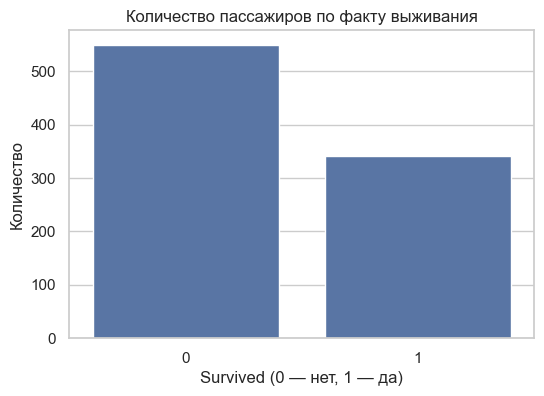

,Доля
Survived,
0,0.616162
1,0.383838


In [3]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x="Survived", ax=ax)
ax.set(title="Количество пассажиров по факту выживания", xlabel="Survived (0 — нет, 1 — да)", ylabel="Количество")
plt.show()
display(df.Survived.value_counts(normalize=True).rename("Доля").to_frame())


Классы распределены неравномерно, поэтому одной доли правильных ответов недостаточно. ROC AUC и метрики по классам дадут более полную картину.


### EDA: пол и класс билета


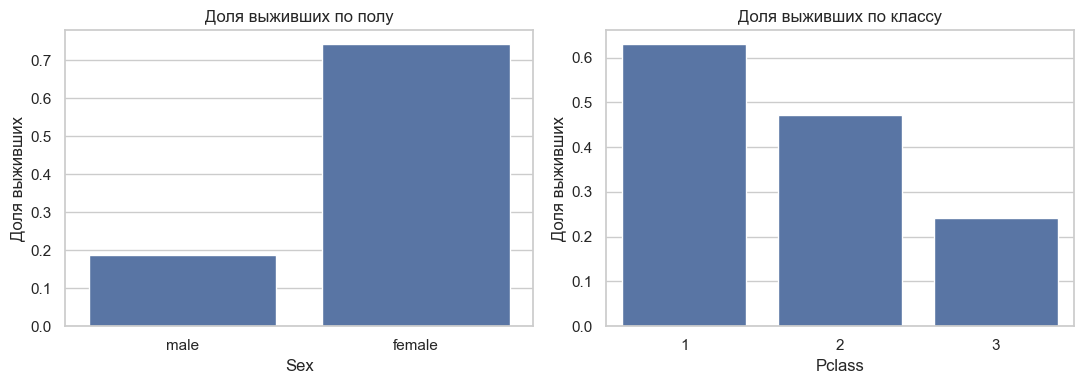

In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None, ax=axes[0])
axes[0].set(title="Доля выживших по полу", ylabel="Доля выживших")
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None, ax=axes[1])
axes[1].set(title="Доля выживших по классу", ylabel="Доля выживших")
plt.tight_layout(); plt.show()


Доли выживших отличаются по полу и классу билета, но наблюдаемая связь не означает причинность. Включим эти признаки в модель.


### EDA: возраст, тариф и порт посадки


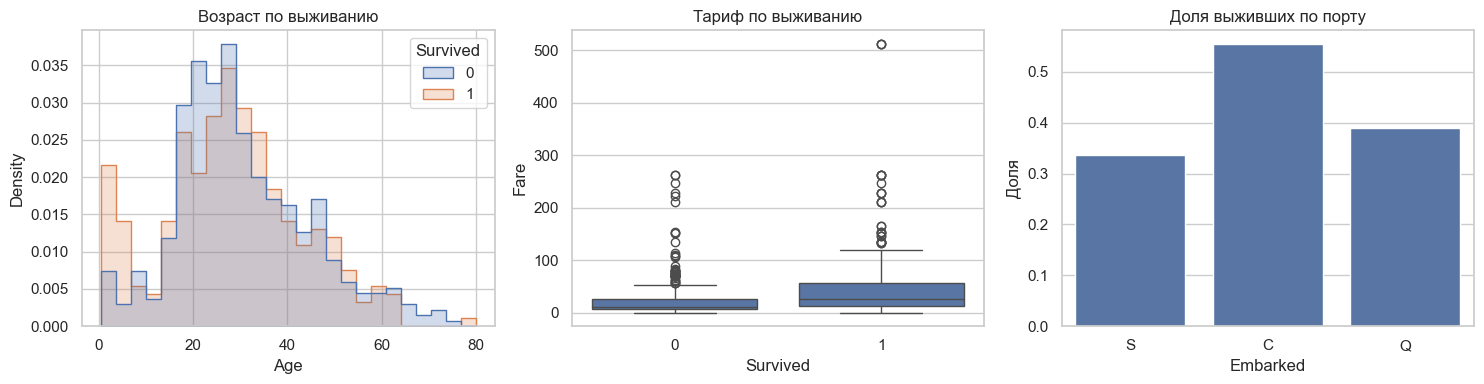

In [5]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Возраст по выживанию")
sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1]); axes[1].set(title="Тариф по выживанию")
sns.barplot(data=df, x="Embarked", y="Survived", errorbar=None, ax=axes[2]); axes[2].set(title="Доля выживших по порту", ylabel="Доля")
plt.tight_layout(); plt.show()


Распределения возраста и тарифа различаются между группами, при этом тариф имеет выбросы. Пропуски числовых признаков будут заполняться медианой, категориальных — наиболее частым значением внутри пайплайна.


### Корреляция признаков с таргетом

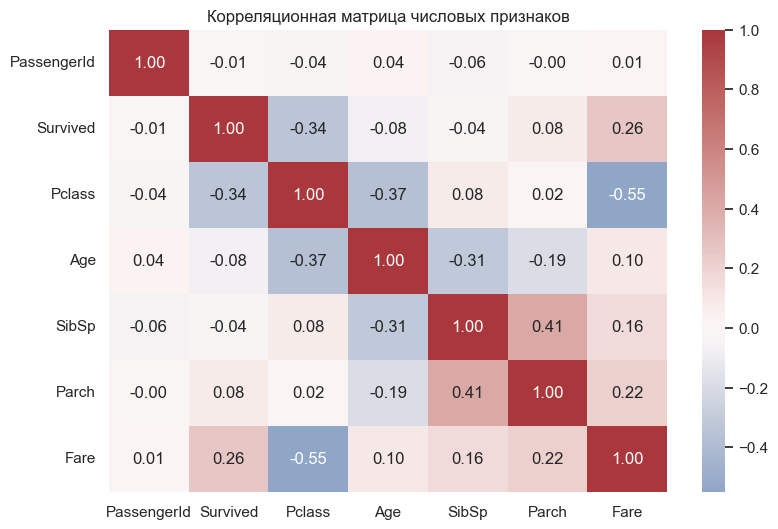

,Корреляция с Survived
Pclass,-0.338481
Fare,0.257307
Parch,0.081629
Age,-0.077221
SibSp,-0.035322
PassengerId,-0.005007


In [6]:
corr = df.select_dtypes(include=np.number).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Корреляционная матрица числовых признаков")
plt.show()
display(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).to_frame("Корреляция с Survived"))


Таблица показывает линейную связь числовых признаков с Survived. Присутствует слабая корреляция.


### 3. Feature Engineering

In [7]:
def make_features(frame):
    out = frame.copy()
    out["Title"] = out["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    out["Title"] = out["Title"].replace({"Mlle":"Miss", "Ms":"Miss", "Mme":"Mrs"})
    out["Title"] = out["Title"].where(out["Title"].isin(["Mr","Mrs","Miss","Master"]), "Rare")
    out["FamilySize"] = out["SibSp"].fillna(0) + out["Parch"].fillna(0) + 1
    out["IsAlone"] = (out["FamilySize"] == 1).astype(int)
    out["Deck"] = out["Cabin"].astype("string").str[0].fillna("Unknown")
    out["TicketPrefix"] = (out["Ticket"].astype(str).str.upper().str.replace(r"[./]", "", regex=True).str.extract(r"([A-Z]+)", expand=False).fillna("NUM"))
    return out.drop(columns=[x for x in ["PassengerId","Name","Ticket","Cabin"] if x in out.columns])

X = make_features(df.drop(columns="Survived"))
y = df["Survived"].astype(int)
display(pd.concat([X[["FamilySize","IsAlone"]], y.rename("Survived")], axis=1).corr()["Survived"].drop("Survived").to_frame("Корреляция новых числовых признаков"))


,Корреляция новых числовых признаков
FamilySize,0.016639
IsAlone,-0.203367


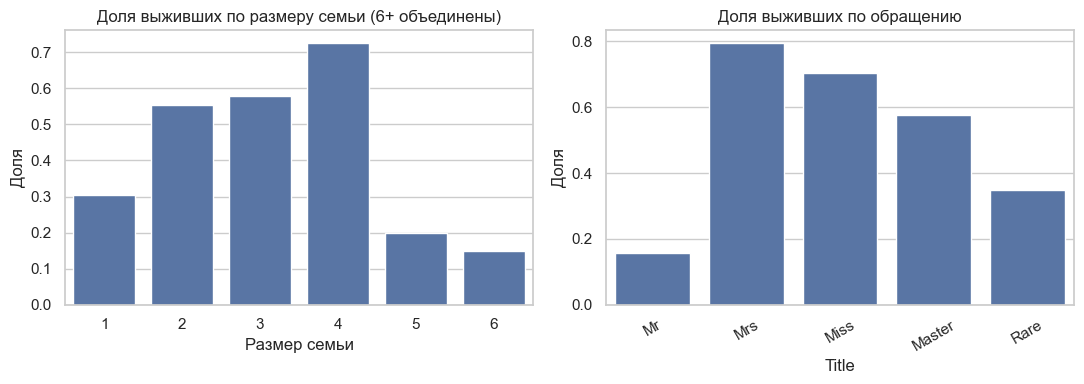

In [8]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(x=X["FamilySize"].clip(upper=6), y=y, errorbar=None, ax=axes[0]); axes[0].set(title="Доля выживших по размеру семьи (6+ объединены)", xlabel="Размер семьи", ylabel="Доля")
sns.barplot(x=X["Title"], y=y, errorbar=None, ax=axes[1]); axes[1].set(title="Доля выживших по обращению", ylabel="Доля")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()


Графики и корреляции позволяют оценить новые признаки до моделирования. Их совместную полезность дополнительно проверим по кросс-валидации и permutation importance.


### 4. Разделение данных и препроцессинг


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
prep = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (712, 12) Test: (179, 12)


### 5. Простая модель и модели разных семейств


In [10]:
models = {
    "Логистическая регрессия": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Дерево решений": DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Случайный лес": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Градиентный бустинг": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE),
    "Нейронная сеть MLP": MLPClassifier(hidden_layer_sizes=(32,16), alpha=0.01, max_iter=1200, early_stopping=True, random_state=RANDOM_STATE)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc":"roc_auc", "accuracy":"accuracy"}
pipelines = {}
rows = []
for name, estimator in models.items():
    pipe = Pipeline([("prep", prep), ("model", estimator)])
    pipelines[name] = pipe
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Модель":name, "ROC AUC среднее":scores["test_roc_auc"].mean(), "ROC AUC std":scores["test_roc_auc"].std(), "Accuracy среднее":scores["test_accuracy"].mean(), "Accuracy std":scores["test_accuracy"].std()})
cv_results = pd.DataFrame(rows).sort_values("ROC AUC среднее", ascending=False).reset_index(drop=True)
display(cv_results)
best_name = cv_results.loc[0,"Модель"]
best_model = pipelines[best_name]
print("Лучшая модель по среднему ROC AUC на 5 фолдах:", best_name)


,Модель,ROC AUC среднее,ROC AUC std,Accuracy среднее,Accuracy std
0,Градиентный бустинг,0.892097,0.020253,0.811819,0.021280
1,Случайный лес,0.884543,0.023812,0.827312,0.032169
2,Логистическая регрессия,0.871998,0.020234,0.814666,0.034884
3,Дерево решений,0.856083,0.035137,0.778154,0.026292
4,Нейронная сеть MLP,0.847491,0.024501,0.787935,0.020450


Лучшая модель по среднему ROC AUC на 5 фолдах: Градиентный бустинг


Модели сравниваются на одинаковых пяти фолдах. Выбор делаем по среднему ROC AUC, а стандартное отклонение показывает стабильность результата. Тестовая часть не участвует в выборе модели.


### 6. Финальная оценка и Feature Importances

Выбранная модель: Градиентный бустинг
Test accuracy: 0.804
Test ROC AUC: 0.858
              precision    recall  f1-score   support

    Не выжил       0.83      0.85      0.84       110
       Выжил       0.76      0.72      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



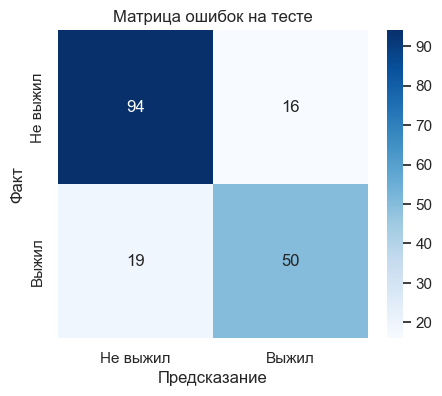

In [11]:
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:,1]
print("Выбранная модель:", best_name)
print(f"Test accuracy: {accuracy_score(y_test,y_pred):.3f}")
print(f"Test ROC AUC: {roc_auc_score(y_test,y_prob):.3f}")
print(classification_report(y_test, y_pred, target_names=["Не выжил","Выжил"]))
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True, fmt="d", cmap="Blues", xticklabels=["Не выжил","Выжил"], yticklabels=["Не выжил","Выжил"], ax=ax)
ax.set(title="Матрица ошибок на тесте", xlabel="Предсказание", ylabel="Факт")
plt.show()


,Permutation importance
Title,0.090626
Sex,0.046588
FamilySize,0.025441
Deck,0.019802
Pclass,0.016614
Fare,0.016038
TicketPrefix,0.011248
Age,0.006624
Embarked,0.004694
SibSp,0.002431


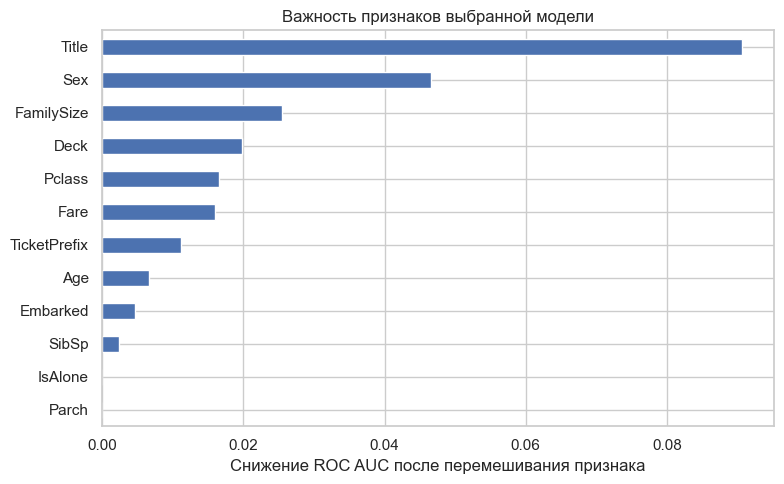

In [12]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(importance.to_frame("Permutation importance"))
ax = importance.sort_values().plot.barh(figsize=(8,5), title="Важность признаков выбранной модели")
ax.set_xlabel("Снижение ROC AUC после перемешивания признака")
plt.tight_layout(); plt.show()


### 7. Итоговые выводы по результатам запуска

EDA и признаки

- В выборке 891 пассажир: 61,6% не выжили и 38,4% выжили. Классы умеренно несбалансированы, поэтому для сравнения моделей использован ROC AUC наряду с accuracy.
- Пропуски обнаружены в Age (177 значений), Cabin (687) и Embarked (2). Импутация и кодирование выполняются внутри пайплайнов моделей.
- Среди исходных числовых признаков заметнее всего линейная связь с выживанием у Pclass (−0,338) и Fare (+0,257). Отрицательная связь Pclass означает, что с ростом номера класса выживаемость в среднем ниже. Корреляция не доказывает причинность и может не отражать нелинейные эффекты.
- Новый признак FamilySize имеет почти нулевую парную корреляцию с Survived (+0,017), тогда как IsAlone связан отрицательно (−0,203). Однако полезность признака определяется также совместным вкладом в модель.

Лучший средний ROC AUC на стратифицированной кросс-валидации из пяти фолдов показал градиентный бустинг: 0,892 ± 0,020. Далее идут случайный лес (0,885 ± 0,024) и логистическая регрессия (0,872 ± 0,020). По средней accuracy случайный лес немного выше бустинга: 0,827 против 0,812. Поэтому выбор бустинга сделан по заранее выбранному критерию ROC AUC; при приоритете accuracy стоит отдельно рассмотреть случайный лес.

На отложенной тестовой выборке градиентный бустинг получил ROC AUC 0,858 и accuracy 0,804. Для класса «выжил» precision равен 0,76, recall — 0,72: модель распознаёт около 72% выживших. Тестовый ROC AUC на 0,034 ниже среднего CV, что указывает на некоторое снижение качества на отложенных данных; оценка остаётся ориентировочной из-за небольшого размера выборки.

Наибольшая permutation importance на тесте у Title (0,091), Sex (0,047), FamilySize (0,025) и Deck (0,020). Далее идут Pclass и Fare (примерно 0,016 каждый). Перемешивание Parch и IsAlone почти не изменило ROC AUC в этом прогоне. Важность показывает вклад признака в конкретную модель, а не причинное влияние; коррелирующие признаки могут делить между собой вклад.

Итог: среди проверенных моделей выбираем градиентный бустинг по среднему ROC AUC на пяти фолдах. На отложенной части качество составило ROC AUC 0,858 и accuracy 0,804. Для дальнейшего улучшения можно отдельно настроить порог классификации, сравнить его с результатом случайного леса и проверить стабильность важностей на повторных разбиениях.
